# Three bases for a beam with a soft segment: monomials, vibration modes and finite elements

Companion notebook to *Variational Methods in Computational Mechanics* (S. Vidoli),
Chapter 6, Section "A Priori Error Estimates", Example "Three Bases for a Beam with a Soft Segment".

A cantilever of unit length, clamped at $x = 0$ and free at $x = 1$, carries a uniform load $p = 1$. Its bending
stiffness is $EI = 1$, except on the segment $0.4 < x < 0.6$, where it drops to $EI = 0.7$ (a weakened or damaged
region). The Galerkin (Ritz) method minimizes the energy
$$\mathcal{E}(w) = \int_0^1 \Big( \tfrac{1}{2}\, EI\, (w'')^2 - p\, w \Big)\, dx, \qquad w(0) = w'(0) = 0,$$
over the span of $N$ trial functions $\varphi_1, \dots, \varphi_N$, by solving
$$\mathbf{K}\mathbf{U} = \mathbf{f}, \qquad K_{ij} = \int_0^1 EI\, \varphi_i''\, \varphi_j''\, dx, \qquad
  f_i = \int_0^1 p\, \varphi_i\, dx .$$
The beam is statically determinate: the bending moment is $M = \tfrac{1}{2}p(1-x)^2$ whatever the stiffness, and
the curvature $w'' = M/EI$ **jumps** at $x = 0.4$ and $x = 0.6$. The exact energy
$\mathcal{E}(w) = -\tfrac{1}{2}\int_0^1 M^2/EI\, dx$ is known, and the relative error in the energy norm of an
approximation $w_h$ follows from its energy alone:
$$\frac{\|w - w_h\|_a}{\|w\|_a} = \sqrt{\frac{\mathcal{E}(w_h) - \mathcal{E}(w)}{-\mathcal{E}(w)}} .$$

The **same** problem is solved with three bases:
1. the monomials $x^2, x^3, \dots, x^{N+1}$;
2. the vibration modes of the **uniform** cantilever (Section 6.2), which satisfy all its boundary conditions and
   are orthogonal for a uniform stiffness;
3. the Hermite cubic finite elements of Section 6.3.2 on a uniform mesh, two unknowns per node, either with nodes
   at the two jumps of the stiffness ($N_e$ a multiple of 5) or with nodes elsewhere.

For each of them we watch two numbers as $N$ grows: the energy error, and the condition number $\kappa(\mathbf{K})$,
which measures how many digits the computer loses in solving the linear system.

**How to use it.** Run the cells in order (*Runtime → Run all* in Colab). Then change the parameters in the next
cell and run everything again.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

# ---------------------------------------------------------------- PARAMETERS
EI_soft  = 0.7               # stiffness of the soft segment (EI = 1 elsewhere); 1.0 = uniform beam
x1, x2   = 0.4, 0.6          # ends of the soft segment
p        = 1.0               # uniform load
N_mono   = range(1, 19)      # numbers of monomials
N_modes  = [1, 2, 4, 6, 8, 10, 16, 20, 32, 40, 64, 80]  # numbers of vibration modes
Ne_al    = [5, 10, 15, 20, 30]  # Hermite elements with nodes at x1, x2 (N = 2 Ne unknowns)
Ne_nal   = [3, 6, 12, 24, 48]  # Hermite elements with nodes elsewhere
N_show   = 10                # number of unknowns of the approximations plotted at the end
# ---------------------------------------------------------------------------

## 1. Ingredients

Every integral is computed with Gauss–Legendre quadrature on a subdivision of $(0, 1)$ into 600 equal intervals
of 16 points each: the jumps of the stiffness and the nodes of every mesh used below fall on interval ends, so
piecewise smooth integrands are integrated to round-off. Each basis function is stored through its values and
its curvature at the quadrature points, which is all that $\mathbf{K}$ and $\mathbf{f}$ need, and the same
function `galerkin` serves the three bases.

Besides $\kappa(\mathbf{K})$ we also compute the condition number of the *diagonally scaled* matrix
$\mathbf{D}^{-1/2}\mathbf{K}\mathbf{D}^{-1/2}$, $\mathbf{D} = \mathrm{diag}(\mathbf{K})$, which is what we get by
normalizing every basis function in energy. This rescaling costs nothing, and removes the part of the
ill-conditioning that is only due to the different sizes of the basis functions.

In [2]:
def quadrature(nq, n=16):
    """Gauss-Legendre points and weights on (0,1) divided into nq equal intervals."""
    g, wg = np.polynomial.legendre.leggauss(n)
    x = np.concatenate([(e + (g + 1) / 2) / nq for e in range(nq)])
    return x, np.concatenate([wg / 2 / nq] * nq)

EI = lambda x: np.where((x > x1) & (x < x2), EI_soft, 1.0)
xq, wq = quadrature(600)
E_exact = -0.5 * np.sum(wq * (0.5 * p * (1 - xq)**2)**2 / EI(xq))

def galerkin(phi, d2):
    """phi, d2: arrays (N, number of points) with the basis functions and their curvatures."""
    K = (d2 * EI(xq) * wq) @ d2.T
    f = (phi * p) @ wq
    U = np.linalg.solve(K, f)
    E = -0.5 * U @ f                                   # energy at the minimum = -1/2 (work of the load)
    err = np.sqrt(max(E - E_exact, 0.0) / -E_exact)    # round-off can make E - E_exact slightly negative
    d = 1 / np.sqrt(np.diag(K))
    return err, np.linalg.cond(K), np.linalg.cond(K * d[:, None] * d[None, :]), U

print(f"exact energy = {E_exact:.10f}")

exact energy = -0.0257234286


## 2. The three bases

**Monomials.** $\varphi_k = x^{k+1}$, $k = 1, \dots, N$, satisfy $w(0) = w'(0) = 0$.

**Vibration modes of the uniform cantilever.** $\varphi_k'''' = \mu_k^4 \varphi_k$ with the clamp conditions at
$x = 0$ and the free-end conditions $\varphi_k''(1) = \varphi_k'''(1) = 0$; the $\mu_k$ are the roots of
$1 + \cos\mu\cosh\mu = 0$. The hyperbolic part is written with decaying exponentials only, to avoid the
cancellations of $\cosh\mu x - \sinh\mu x$ for large $\mu$.

**Hermite cubics.** On each element of length $h$, with $s = (x - x_e)/h$, the four shape functions
$$N_1 = 1 - 3s^2 + 2s^3,\quad N_2 = h(s - 2s^2 + s^3),\quad N_3 = 3s^2 - 2s^3,\quad N_4 = h(s^3 - s^2)$$
multiply the displacement and the rotation at the left node and at the right node. The clamp removes the two
unknowns of the node $x = 0$.

Each function returns values, curvatures and third derivatives (for the shear force) at the points `x`.

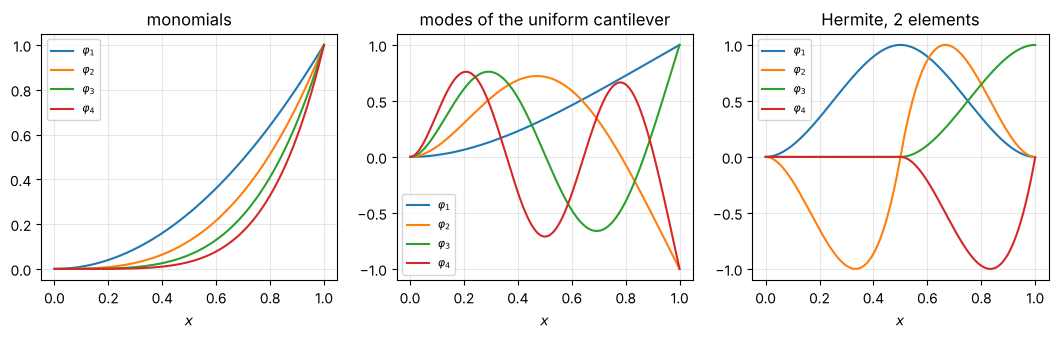

In [3]:
def monomials(N, x):
    k = np.arange(2, N + 2)[:, None]
    return x**k, k * (k - 1) * x**(k - 2), k * (k - 1) * (k - 2) * x**np.maximum(k - 3, 0)

f_char = lambda m: 1 + np.cos(m) * np.cosh(m)
mu = np.array([brentq(f_char, 1, 2.5)] +
              [brentq(f_char, (k - 0.5) * np.pi - 0.5, (k - 0.5) * np.pi + 0.5) for k in range(2, 101)])

def modes(N, x):
    out = [[], [], []]
    for m in mu[:N]:
        den = np.sinh(m) + np.sin(m); s = (np.cosh(m) + np.cos(m)) / den
        A = np.exp(m) * (np.sin(m) - np.cos(m) - np.exp(-m)) / (2 * den); B = (1 + s) / 2
        e1, e2 = A * np.exp(m * (x - 1)), B * np.exp(-m * x)       # cosh - s sinh = e1 + e2
        out[0].append(e1 + e2 - np.cos(m * x) + s * np.sin(m * x))
        out[1].append(m**2 * (e1 + e2 + np.cos(m * x) - s * np.sin(m * x)))
        out[2].append(m**3 * (e1 - e2 - np.sin(m * x) - s * np.cos(m * x)))
    return [np.array(o) for o in out]

def hermite(Ne, x):
    h = 1 / Ne
    e = np.minimum((x / h).astype(int), Ne - 1); s = x / h - e
    shapes = [1 - 3*s**2 + 2*s**3, h*(s - 2*s**2 + s**3), 3*s**2 - 2*s**3, h*(s**3 - s**2)]
    curv   = [(-6 + 12*s) / h**2, (-4 + 6*s) / h, (6 - 12*s) / h**2, (6*s - 2) / h]
    third  = [12 / h**3 + 0*s, 6 / h**2 + 0*s, -12 / h**3 + 0*s, 6 / h**2 + 0*s]
    out = [np.zeros((2 * (Ne + 1), x.size)) for _ in range(3)]; cols = np.arange(x.size)
    for j in range(4):
        for o, v in zip(out, (shapes, curv, third)):
            np.add.at(o, (2 * e + j, cols), v[j])
    return [o[2:] for o in out]     # drop displacement and rotation of the clamped node

fig, axs = plt.subplots(1, 3, figsize=(13, 3.2))
xs = (np.arange(1000) + 0.5) / 1000     # plotting points, never exactly on a node or a jump
for ax, (name, basis, n) in zip(axs, [("monomials", monomials, 4), ("modes of the uniform cantilever", modes, 4),
                                       ("Hermite, 2 elements", hermite, 2)]):
    for k, ph in enumerate(basis(n, xs)[0]):
        ax.plot(xs, ph / np.max(np.abs(ph)), label=f"$\\varphi_{k+1}$")
    ax.set_title(name); ax.set_xlabel("$x$"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.show()

## 3. Error and conditioning


monomials
   N   energy error   kappa(K)   kappa(scaled K)
   1     6.52e-01    1.00e+00    1.00e+00
   2     1.40e-01    1.85e+01    1.32e+01
   3     7.52e-02    3.65e+02    2.94e+02
   4     7.52e-02    8.46e+03    7.35e+03
   5     6.43e-02    2.40e+05    2.22e+05
   6     6.41e-02    6.64e+06    6.39e+06
   7     5.35e-02    2.02e+08    2.01e+08
   8     5.31e-02    6.05e+09    6.18e+09
   9     4.43e-02    1.88e+11    1.96e+11
  10     4.37e-02    5.90e+12    6.26e+12
  11     3.78e-02    1.85e+14    1.99e+14
  12     3.69e-02    6.68e+15    7.47e+15
  13     3.74e-02    3.23e+17    1.04e+17
  14     3.58e-02    3.53e+17    1.28e+17
  15     3.56e-02    8.10e+16    7.42e+16
  16     3.17e-02    4.63e+17    3.15e+17
  17     7.21e-02    2.96e+18    3.41e+17
  18     3.33e-02    1.26e+18    3.79e+17

modes
   N   energy error   kappa(K)   kappa(scaled K)
   1     8.48e-02    1.00e+00    1.00e+00
   2     7.85e-02    3.60e+01    1.13e+00
   4     5.54e-02    1.13e+03    1.30e+00
  

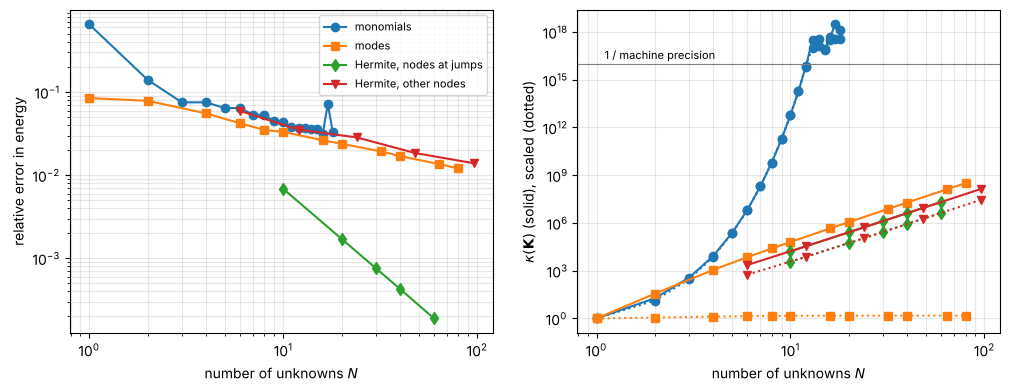

In [4]:
run = lambda basis, n: galerkin(*basis(n, xq)[:2])[:3]
res = {"monomials":              [(N, *run(monomials, N)) for N in N_mono],
       "modes":                  [(N, *run(modes, N)) for N in N_modes],
       "Hermite, nodes at jumps": [(2 * Ne, *run(hermite, Ne)) for Ne in Ne_al],
       "Hermite, other nodes":    [(2 * Ne, *run(hermite, Ne)) for Ne in Ne_nal]}

for name, rows in res.items():
    print(f"\n{name}\n   N   energy error   kappa(K)   kappa(scaled K)")
    for N, err, k, ks in rows:
        print(f"{N:4d}   {err:10.2e}   {k:9.2e}   {ks:9.2e}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2))
for (name, rows), m in zip(res.items(), "osdv"):
    N, err, k, ks = np.array(rows).T
    good = err > 0
    a1.loglog(N[good], err[good], m + "-", label=name)
    l, = a2.loglog(N, k, m + "-", label=name)
    a2.loglog(N, ks, m + ":", color=l.get_color())
a1.set_xlabel("number of unknowns $N$"); a1.set_ylabel("relative error in energy"); a1.legend(fontsize=8)
a2.set_xlabel("number of unknowns $N$"); a2.set_ylabel(r"$\kappa(\mathbf{K})$ (solid), scaled (dotted)")
a2.axhline(1e16, color="gray", lw=0.8); a2.text(1.1, 2e16, "1 / machine precision", fontsize=8)
for a in (a1, a2): a.grid(True, which="both", alpha=0.3)
plt.show()

* **Monomials** lose the speed they had for a smooth stiffness (Example "Monomials: Fast but Fragile" of
  Section 6.1.3): the exact curvature jumps, and no polynomial can follow it. The error decreases slowly, and
  before it gets small the condition number reaches $10^{16}$ and round-off takes over: slow *and* fragile.
* **Vibration modes** of the uniform cantilever are well conditioned: after the diagonal scaling $\kappa$ stays
  below 2, because the stiffness matrix is almost diagonal. But they are smooth functions too, and converge like
  $N^{-1/2}$.
* **Hermite elements with nodes at the jumps** converge like $h^2 \sim N^{-2}$, as for a smooth stiffness: inside
  each element the solution is smooth, and the error estimates of Section 6.3.3 apply element by element. With
  only ten unknowns they are already ten times better than everything else.
* **The same elements with nodes elsewhere** drop to $N^{-1/2}$, like the modes: an element that contains a jump
  of the curvature must approximate it with a cubic.

The advantage of functions with local support is not the shape of the element, but the freedom to place the nodes
where the data are rough.

## 4. Curvature and bending moment

The bending moment $M = EI\,w''$ is continuous, and so is the exact shear force $T = -M'$; the curvature $w'' = M/EI$
jumps with the stiffness.

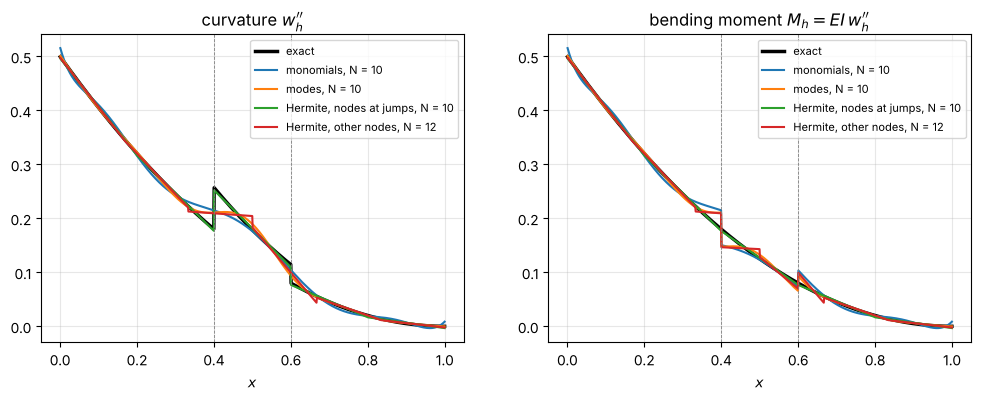

In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
M_ex = 0.5 * p * (1 - xs)**2
a1.plot(xs, M_ex / EI(xs), "k", lw=2.5, label="exact"); a2.plot(xs, M_ex, "k", lw=2.5, label="exact")
for name, basis, n in [("monomials", monomials, N_show), ("modes", modes, N_show),
                       ("Hermite, nodes at jumps", hermite, N_show // 2),
                       ("Hermite, other nodes", hermite, N_show // 2 + 1)]:
    U = galerkin(*basis(n, xq)[:2])[3]
    phi, d2, d3 = basis(n, xs)
    a1.plot(xs, U @ d2, label=f"{name}, N = {len(U)}")
    a2.plot(xs, EI(xs) * (U @ d2), label=f"{name}, N = {len(U)}")
a1.set_title("curvature $w_h''$"); a2.set_title("bending moment $M_h = EI\\, w_h''$")
for a in (a1, a2):
    a.set_xlabel("$x$"); a.grid(alpha=0.3); a.legend(fontsize=8)
    for xj in (x1, x2): a.axvline(xj, color="gray", lw=0.6, ls="--")
plt.show()

The smooth bases smear the jumps of the curvature over the whole beam, and their bending moments jump where the
exact one is continuous. The Hermite elements with nodes at $x = 0.4$ and $0.6$ follow the jumps exactly; with
nodes elsewhere the jumps are smeared over the elements that contain them.

## Things to try
1. Set `EI_soft = 1.0` (uniform beam): the exact solution is a polynomial of degree 4, and the monomials recover it
   with $N = 3$ (the printed error, about $10^{-7}$, is the square root of the round-off on the energy); the modes
   diagonalize $\mathbf{K}$ exactly, and $\kappa$ of the scaled matrix equals 1.
2. Make the soft segment much softer, `EI_soft = 0.1`: which bases suffer most? Does the rate of convergence
   change, or only the constant?
3. Move the soft segment to `x1, x2 = 0.33, 0.5` and check which meshes now have nodes at the jumps.
4. Plot the shear force $T_h = -(EI\, w_h'')'$, using the third derivatives returned by the basis functions, and
   compare it with the exact $T = p(1 - x)$: which basis gives the worst shear force near the clamp, and why?
5. Compute the tip deflection $w_h(1)$ for the Hermite elements with nodes at the jumps: it is exact to round-off.
   Section 6.3.1 explains why.